In [1]:

from pathlib import Path
import pandas as pd

# Find the main project folder
project_path = Path.cwd()

# Load the revised nuclear power plant dataset
dataset_path = project_path / "prepared_data" / "npp_revised.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nClass distribution:")
print(df["Label"].value_counts())

print("\nNumber of scenarios:", df["Scenario_ID"].nunique())

print("\nFirst 5 rows:")
display(df.head())


Dataset loaded successfully!
Dataset shape: (10339, 100)

Class distribution:
Label
1    9730
0     609
Name: count, dtype: int64

Number of scenarios: 17

First 5 rows:


,TIME,P,TAVG,THA,THB,TCA,TCB,WRCA,WRCB,PSGA,...,TCRT,TSLP,PPM,RRCA,RRCB,RRCO,WFLB,Scenario,Scenario_ID,Label
0,0,155.500015,310.000000,327.823975,327.823212,292.176056,292.176788,16515.818359,33031.636719,67.000031,...,50,50.0,200.0,1.0,1.0,1.0,0,00 - Normal Operation,0,0
1,1,155.494339,309.993713,327.823273,327.822479,292.175049,292.175842,16515.818359,33031.636719,66.999924,...,50,50.0,200.0,1.0,1.0,1.0,0,00 - Normal Operation,0,0
2,2,155.486084,309.987915,327.821381,327.820618,292.173492,292.174286,16515.818359,33031.636719,66.999176,...,50,50.0,200.0,1.0,1.0,1.0,0,00 - Normal Operation,0,0
3,3,155.478165,309.982910,327.818756,327.817932,292.171509,292.172272,16515.818359,33031.636719,66.997894,...,50,50.0,200.0,1.0,1.0,1.0,0,00 - Normal Operation,0,0
4,4,155.471954,309.979370,327.815796,327.814972,292.169220,292.170013,16515.818359,33031.636719,66.996246,...,50,50.0,200.0,1.0,1.0,1.0,0,00 - Normal Operation,0,0


In [2]:

# Step 2: Inspect the scenarios in our dataset

scenario_summary = (
    df.groupby(["Scenario_ID", "Scenario", "Label"])
      .agg(
          Records=("TIME", "size"),
          Start_Time=("TIME", "min"),
          End_Time=("TIME", "max")
      )
      .reset_index()
      .sort_values("Scenario_ID")
)

print("SCENARIO SUMMARY")
display(scenario_summary)

print("\nNumber of normal scenarios:",
      df[df["Label"] == 0]["Scenario_ID"].nunique())

print("Number of fault scenarios:",
      df[df["Label"] == 1]["Scenario_ID"].nunique())

print("\nDuplicate scenario/time combinations:",
      df.duplicated(subset=["Scenario_ID", "TIME"]).sum())


SCENARIO SUMMARY


,Scenario_ID,Scenario,Label,Records,Start_Time,End_Time
0,0,00 - Normal Operation,0,609,0,608
1,1,01 - Loss of Coolant Accident (Hot Leg),1,605,1,605
2,2,02 - Loss of Coolant Accident (Cold Leg),1,602,1,602
3,3,03 - Steam Line Break Inside Containment,1,602,1,602
4,4,04 - Steam Line Break Outside Containment,1,602,1,602
5,6,06 - Loss of AC Power,1,636,1,636
6,7,07 - Loss of Flow (Locked Rotor),1,607,1,607
7,9,09 - Turbine Trip,1,602,1,602
8,10,10 - Steam Generator A Tube Rupture,1,603,1,603
9,11,11 - Steam Generator B Tube Rupture,1,606,1,606



Number of normal scenarios: 1
Number of fault scenarios: 16

Duplicate scenario/time combinations: 0


In [3]:

# Step 3: Create training, validation, and testing datasets

from sklearn.model_selection import train_test_split

# Identify our 96 sensor features
metadata_columns = ["TIME", "Scenario", "Scenario_ID", "Label"]

feature_columns = [
    col for col in df.columns
    if col not in metadata_columns
]

# Separate normal and fault records
normal_df = df[df["Label"] == 0].sort_values("TIME").copy()
fault_df = df[df["Label"] == 1].copy()

# Split FAULT scenarios into separate groups
fault_ids = sorted(fault_df["Scenario_ID"].unique())

train_ids, remaining_ids = train_test_split(
    fault_ids,
    test_size=6,
    random_state=42
)

val_ids, test_ids = train_test_split(
    remaining_ids,
    test_size=3,
    random_state=42
)

# Split NORMAL data chronologically: 60% / 20% / 20%
n = len(normal_df)
cut1 = int(n * 0.60)
cut2 = int(n * 0.80)

normal_train = normal_df.iloc[:cut1]
normal_val = normal_df.iloc[cut1:cut2]
normal_test = normal_df.iloc[cut2:]

# Combine normal and fault records
train_df = pd.concat([
    normal_train,
    fault_df[fault_df["Scenario_ID"].isin(train_ids)]
])

val_df = pd.concat([
    normal_val,
    fault_df[fault_df["Scenario_ID"].isin(val_ids)]
])

test_df = pd.concat([
    normal_test,
    fault_df[fault_df["Scenario_ID"].isin(test_ids)]
])

# Prepare features and labels
X_train = train_df[feature_columns]
y_train = train_df["Label"]

X_val = val_df[feature_columns]
y_val = val_df["Label"]

X_test = test_df[feature_columns]
y_test = test_df["Label"]

print("Number of sensor features:", len(feature_columns))

print("\nTraining:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nValidation labels:")
print(y_val.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

print("\nFault scenario overlap:",
      len(set(train_ids) & set(val_ids)) +
      len(set(train_ids) & set(test_ids)) +
      len(set(val_ids) & set(test_ids)))

print("\nTraining fault scenarios:", sorted(train_ids))
print("Validation fault scenarios:", sorted(val_ids))
print("Testing fault scenarios:", sorted(test_ids))


Number of sensor features: 96

Training: (6449, 96)
Validation: (1945, 96)
Testing: (1945, 96)

Training labels:
Label
1    6084
0     365
Name: count, dtype: int64

Validation labels:
Label
1    1823
0     122
Name: count, dtype: int64

Testing labels:
Label
1    1823
0     122
Name: count, dtype: int64

Fault scenario overlap: 0

Training fault scenarios: [3, 4, 6, 9, 10, 11, 12, 15, 17, 20]
Validation fault scenarios: [7, 18, 19]
Testing fault scenarios: [1, 2, 16]


In [4]:

# Step 4: Check for identical sensor measurements across splits

import pandas as pd

# Create sensor-pattern fingerprints
train_patterns = pd.util.hash_pandas_object(
    X_train, index=False
)

val_patterns = pd.util.hash_pandas_object(
    X_val, index=False
)

test_patterns = pd.util.hash_pandas_object(
    X_test, index=False
)

# Convert to sets for comparison
train_set = set(train_patterns)
val_set = set(val_patterns)
test_set = set(test_patterns)

print("DATA LEAKAGE CHECK")
print("------------------")

print("Training vs Validation:",
      len(train_set & val_set))

print("Training vs Testing:",
      len(train_set & test_set))

print("Validation vs Testing:",
      len(val_set & test_set))

print("\nUnique training patterns:", len(train_set))
print("Unique validation patterns:", len(val_set))
print("Unique testing patterns:", len(test_set))


DATA LEAKAGE CHECK
------------------
Training vs Validation: 0
Training vs Testing: 0
Validation vs Testing: 0

Unique training patterns: 6447
Unique validation patterns: 1945
Unique testing patterns: 1945


In [5]:

# Step 5: Random Forest model complexity experiment

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score
import pandas as pd

depth_values = [2, 4, 6, 10, 15, None]

rf_results = []

for depth in depth_values:

    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_score = balanced_accuracy_score(y_train, train_pred)
    val_score = balanced_accuracy_score(y_val, val_pred)

    rf_results.append({
        "Max_Depth": str(depth),
        "Train_Balanced_Accuracy": train_score,
        "Validation_Balanced_Accuracy": val_score,
        "Generalization_Gap": train_score - val_score
    })

rf_results_df = pd.DataFrame(rf_results)

print("RANDOM FOREST COMPLEXITY RESULTS")
display(rf_results_df.round(4))


RANDOM FOREST COMPLEXITY RESULTS


,Max_Depth,Train_Balanced_Accuracy,Validation_Balanced_Accuracy,Generalization_Gap
0,2,0.9256,0.7216,0.2040
1,4,0.9706,0.3003,0.6702
2,6,0.9746,0.3022,0.6724
3,10,0.9998,0.3121,0.6877
4,15,0.9998,0.3557,0.6441
5,None,0.9998,0.3673,0.6326


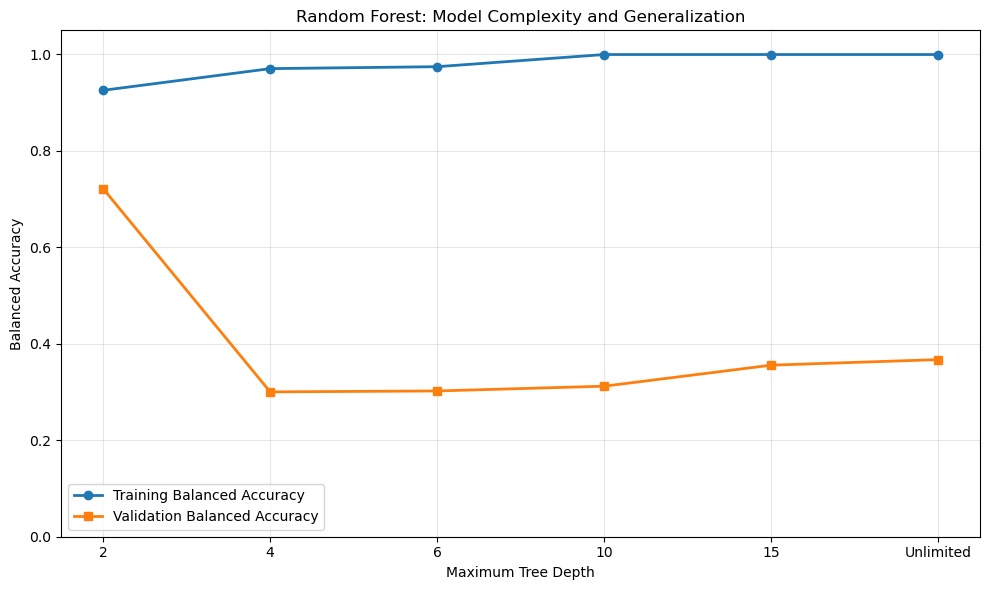

Graph saved successfully!


In [6]:

# Step 6: Visualize Random Forest model complexity

import matplotlib.pyplot as plt

plot_df = rf_results_df.copy()

# Treat unlimited depth as a separate category
x_labels = plot_df["Max_Depth"].replace({"None": "Unlimited"})

plt.figure(figsize=(10, 6))

plt.plot(
    x_labels,
    plot_df["Train_Balanced_Accuracy"],
    marker="o",
    linewidth=2,
    label="Training Balanced Accuracy"
)

plt.plot(
    x_labels,
    plot_df["Validation_Balanced_Accuracy"],
    marker="s",
    linewidth=2,
    label="Validation Balanced Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Balanced Accuracy")
plt.title("Random Forest: Model Complexity and Generalization")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Save graph for our project report
plt.savefig(
    project_path / "results" / "rf_complexity_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved successfully!")


In [7]:

# Step 7: Examine Random Forest prediction errors

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    balanced_accuracy_score
)

# Train the best-performing depth from Step 5
rf_best = RandomForestClassifier(
    n_estimators=100,
    max_depth=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_best.fit(X_train, y_train)

# Predict on validation data only
rf_val_pred = rf_best.predict(X_val)

print("RANDOM FOREST - VALIDATION ERROR ANALYSIS")
print("-----------------------------------------")

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_val, rf_val_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rf_val_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_val,
    rf_val_pred,
    labels=[0, 1],
    target_names=["Normal", "Fault"],
    zero_division=0
))

# Check performance for each validation fault scenario
val_analysis = val_df.copy()
val_analysis["Prediction"] = rf_val_pred

scenario_results = (
    val_analysis.groupby(["Scenario_ID", "Scenario"])
    .apply(
        lambda group: pd.Series({
            "Records": len(group),
            "Correct": (group["Label"] == group["Prediction"]).sum(),
            "Accuracy": (group["Label"] == group["Prediction"]).mean()
        }),
        include_groups=False
    )
    .reset_index()
)

print("\nPERFORMANCE BY VALIDATION SCENARIO")
display(scenario_results.round(4))


RANDOM FOREST - VALIDATION ERROR ANALYSIS
-----------------------------------------
Balanced Accuracy: 0.7216

Confusion Matrix:
[[ 103   19]
 [ 731 1092]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.12      0.84      0.22       122
       Fault       0.98      0.60      0.74      1823

    accuracy                           0.61      1945
   macro avg       0.55      0.72      0.48      1945
weighted avg       0.93      0.61      0.71      1945


PERFORMANCE BY VALIDATION SCENARIO


,Scenario_ID,Scenario,Records,Correct,Accuracy
0,0,00 - Normal Operation,122.0,103.0,0.8443
1,7,07 - Loss of Flow (Locked Rotor),607.0,606.0,0.9984
2,18,18 - Fuel Handling Accident in Containment,607.0,242.0,0.3987
3,19,19 - Fuel Handling Accident in Auxiliary Building,609.0,244.0,0.4007


In [8]:

# Step 8: XGBoost tuning using unseen validation scenarios

from xgboost import XGBClassifier
from sklearn.metrics import balanced_accuracy_score
import pandas as pd

xgb_results = []

depth_values = [2, 3, 5, 7]
learning_rates = [0.03, 0.1]

for depth in depth_values:
    for lr in learning_rates:

        model = XGBClassifier(
            n_estimators=150,
            max_depth=depth,
            learning_rate=lr,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        val_pred = model.predict(X_val)

        train_score = balanced_accuracy_score(y_train, train_pred)
        val_score = balanced_accuracy_score(y_val, val_pred)

        xgb_results.append({
            "Max_Depth": depth,
            "Learning_Rate": lr,
            "Train_Balanced_Accuracy": train_score,
            "Validation_Balanced_Accuracy": val_score,
            "Generalization_Gap": train_score - val_score
        })

xgb_results_df = pd.DataFrame(xgb_results)

# Sort best validation performance first
xgb_results_df = xgb_results_df.sort_values(
    "Validation_Balanced_Accuracy",
    ascending=False
).reset_index(drop=True)

print("XGBOOST HYPERPARAMETER TUNING RESULTS")
display(xgb_results_df.round(4))

# Show best configuration
best_config = xgb_results_df.iloc[0]

print("\nBest XGBoost Configuration:")
print("Maximum depth:", int(best_config["Max_Depth"]))
print("Learning rate:", best_config["Learning_Rate"])
print("Validation balanced accuracy:",
      round(best_config["Validation_Balanced_Accuracy"], 4))


XGBOOST HYPERPARAMETER TUNING RESULTS


,Max_Depth,Learning_Rate,Train_Balanced_Accuracy,Validation_Balanced_Accuracy,Generalization_Gap
0,5,0.03,0.9986,0.9467,0.0519
1,7,0.03,0.9986,0.9467,0.0519
2,7,0.10,0.9986,0.7745,0.2242
3,5,0.10,0.9986,0.7547,0.2439
4,2,0.03,0.9973,0.6731,0.3242
5,2,0.10,0.9986,0.6670,0.3316
6,3,0.10,0.9986,0.6670,0.3316
7,3,0.03,0.9986,0.6468,0.3518



Best XGBoost Configuration:
Maximum depth: 5
Learning rate: 0.03
Validation balanced accuracy: 0.9467


In [9]:

# Step 9: Detailed validation of the best XGBoost configuration

from xgboost import XGBClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

# Best configuration selected from Step 8
xgb_best = XGBClassifier(
    n_estimators=150,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_best.fit(X_train, y_train)

# Validation predictions
xgb_val_pred = xgb_best.predict(X_val)

print("BEST XGBOOST - VALIDATION ANALYSIS")
print("----------------------------------")

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_val, xgb_val_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, xgb_val_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_val,
    xgb_val_pred,
    labels=[0, 1],
    target_names=["Normal", "Fault"],
    zero_division=0
))

# Analyze each validation scenario
xgb_val_analysis = val_df.copy()
xgb_val_analysis["Prediction"] = xgb_val_pred

scenario_results_xgb = (
    xgb_val_analysis.groupby(["Scenario_ID", "Scenario"])
    .apply(
        lambda group: pd.Series({
            "Records": len(group),
            "Correct": (group["Label"] == group["Prediction"]).sum(),
            "Accuracy": (group["Label"] == group["Prediction"]).mean()
        }),
        include_groups=False
    )
    .reset_index()
)

print("\nXGBOOST PERFORMANCE BY VALIDATION SCENARIO")
display(scenario_results_xgb.round(4))


BEST XGBOOST - VALIDATION ANALYSIS
----------------------------------
Balanced Accuracy: 0.9467

Confusion Matrix:
[[ 109   13]
 [   0 1823]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.89      0.94       122
       Fault       0.99      1.00      1.00      1823

    accuracy                           0.99      1945
   macro avg       1.00      0.95      0.97      1945
weighted avg       0.99      0.99      0.99      1945


XGBOOST PERFORMANCE BY VALIDATION SCENARIO


,Scenario_ID,Scenario,Records,Correct,Accuracy
0,0,00 - Normal Operation,122.0,109.0,0.8934
1,7,07 - Loss of Flow (Locked Rotor),607.0,607.0,1.0000
2,18,18 - Fuel Handling Accident in Containment,607.0,607.0,1.0000
3,19,19 - Fuel Handling Accident in Auxiliary Building,609.0,609.0,1.0000


In [10]:

# Step 10: Save validation results for our final report

from pathlib import Path
import json
import pandas as pd

results_path = project_path / "results"
results_path.mkdir(parents=True, exist_ok=True)

# Save Random Forest complexity experiment
rf_results_df.to_csv(
    results_path / "advanced_rf_complexity.csv",
    index=False
)

# Save XGBoost tuning experiment
xgb_results_df.to_csv(
    results_path / "advanced_xgb_tuning.csv",
    index=False
)

# Save per-scenario validation results
scenario_results_xgb.to_csv(
    results_path / "advanced_xgb_scenario_validation.csv",
    index=False
)

# Save selected configuration
best_xgb_settings = {
    "n_estimators": 150,
    "max_depth": 5,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": 42,
    "selection_metric": "validation_balanced_accuracy",
    "validation_balanced_accuracy": 0.9467
}

with open(
    results_path / "advanced_xgb_configuration.json",
    "w"
) as f:
    json.dump(best_xgb_settings, f, indent=4)

print("Experimental results saved successfully!")
print("\nSaved files:")

for filename in [
    "advanced_rf_complexity.csv",
    "advanced_xgb_tuning.csv",
    "advanced_xgb_scenario_validation.csv",
    "advanced_xgb_configuration.json"
]:
    print("-", filename)


Experimental results saved successfully!

Saved files:
- advanced_rf_complexity.csv
- advanced_xgb_tuning.csv
- advanced_xgb_scenario_validation.csv
- advanced_xgb_configuration.json


In [11]:

# Step 11: Check PyTorch installation

import importlib.util

if importlib.util.find_spec("torch") is not None:
    import torch

    print("PyTorch is installed successfully!")
    print("PyTorch version:", torch.__version__)
    print("GPU available:", torch.cuda.is_available())

else:
    print("PyTorch is not installed.")
    print("We need to install it before continuing.")

print("\nNormal training records:",
      (y_train == 0).sum())

print("Number of sensor features:",
      X_train.shape[1])


PyTorch is installed successfully!
PyTorch version: 2.5.1+cpu
GPU available: False

Normal training records: 365
Number of sensor features: 96


In [12]:

# Step 12: Prepare sensor data for the Autoencoder

import numpy as np
from sklearn.preprocessing import StandardScaler

# Select normal-operation training measurements only
X_normal_train = X_train.loc[y_train == 0].copy()

# Fit the scaler ONLY on normal training data
scaler_ae = StandardScaler()
scaler_ae.fit(X_normal_train)

# Transform training and validation measurements
X_normal_train_scaled = scaler_ae.transform(X_normal_train)
X_val_scaled = scaler_ae.transform(X_val)

# Also transform normal validation measurements separately
X_normal_val_scaled = scaler_ae.transform(
    X_val.loc[y_val == 0]
)

# Convert to float32 for PyTorch
X_normal_train_scaled = X_normal_train_scaled.astype(np.float32)
X_normal_val_scaled = X_normal_val_scaled.astype(np.float32)
X_val_scaled = X_val_scaled.astype(np.float32)

print("AUTOENCODER DATA PREPARATION")
print("----------------------------")

print("Normal training data:",
      X_normal_train_scaled.shape)

print("Normal validation data:",
      X_normal_val_scaled.shape)

print("All validation data:",
      X_val_scaled.shape)

print("\nTraining data mean:",
      round(float(X_normal_train_scaled.mean()), 4))

print("Training data standard deviation:",
      round(float(X_normal_train_scaled.std()), 4))

print("\nMissing or infinite values:",
      not np.isfinite(X_normal_train_scaled).all())


AUTOENCODER DATA PREPARATION
----------------------------
Normal training data: (365, 96)
Normal validation data: (122, 96)
All validation data: (1945, 96)

Training data mean: -0.0
Training data standard deviation: 0.6535

Missing or infinite values: False


In [13]:

# Step 13: Define our Autoencoder architecture

import torch
import torch.nn as nn

# Make results reproducible
torch.manual_seed(42)

class NuclearAutoencoder(nn.Module):

    def __init__(self, input_dim=96):
        super().__init__()

        # Encoder: compress 96 measurements into 16
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16)
        )

        # Decoder: reconstruct the original measurements
        self.decoder = nn.Sequential(
            nn.Linear(16, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        compressed = self.encoder(x)
        reconstructed = self.decoder(compressed)
        return reconstructed

# Create the Autoencoder model
autoencoder = NuclearAutoencoder(
    input_dim=X_normal_train_scaled.shape[1]
)

# Test its input and output dimensions
sample_input = torch.tensor(
    X_normal_train_scaled[:5],
    dtype=torch.float32
)

sample_output = autoencoder(sample_input)

print("AUTOENCODER ARCHITECTURE")
print("------------------------")

print(autoencoder)

print("\nInput shape:", sample_input.shape)
print("Output shape:", sample_output.shape)

print("\nNumber of trainable parameters:",
      sum(p.numel() for p in autoencoder.parameters()
          if p.requires_grad))


AUTOENCODER ARCHITECTURE
------------------------
NuclearAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=96, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=96, bias=True)
  )
)

Input shape: torch.Size([5, 96])
Output shape: torch.Size([5, 96])

Number of trainable parameters: 17712


In [14]:

# Step 14: Train the Autoencoder with Early Stopping

import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Convert normal training data into PyTorch tensors
train_tensor = torch.tensor(
    X_normal_train_scaled,
    dtype=torch.float32
)

val_tensor = torch.tensor(
    X_normal_val_scaled,
    dtype=torch.float32
)

# Create batches of training data
train_loader = DataLoader(
    TensorDataset(train_tensor),
    batch_size=32,
    shuffle=True
)

# Loss function and optimizer
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    autoencoder.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

# Early stopping settings
max_epochs = 200
patience = 15

best_val_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0

train_losses = []
val_losses = []

for epoch in range(max_epochs):

    # Training
    autoencoder.train()
    total_train_loss = 0

    for (batch,) in train_loader:

        optimizer.zero_grad()

        reconstructed = autoencoder(batch)

        loss = criterion(reconstructed, batch)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * len(batch)

    avg_train_loss = total_train_loss / len(train_tensor)

    # Validation
    autoencoder.eval()

    with torch.no_grad():
        val_reconstructed = autoencoder(val_tensor)
        avg_val_loss = criterion(
            val_reconstructed,
            val_tensor
        ).item()

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    # Early stopping
    if avg_val_loss < best_val_loss - 1e-6:
        best_val_loss = avg_val_loss
        best_model_state = copy.deepcopy(
            autoencoder.state_dict()
        )
        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Train Loss = {avg_train_loss:.6f}, "
            f"Val Loss = {avg_val_loss:.6f}"
        )

    if epochs_without_improvement >= patience:
        print("\nEarly stopping triggered!")
        break

# Restore best-performing model
autoencoder.load_state_dict(best_model_state)

print("\nAUTOENCODER TRAINING COMPLETE")
print("Total epochs:", len(train_losses))
print("Best validation loss:", round(best_val_loss, 6))


Epoch 10: Train Loss = 0.099512, Val Loss = 0.049242
Epoch 20: Train Loss = 0.048584, Val Loss = 0.033556
Epoch 30: Train Loss = 0.023763, Val Loss = 0.019525
Epoch 40: Train Loss = 0.014348, Val Loss = 0.016388
Epoch 50: Train Loss = 0.006440, Val Loss = 0.016705

Early stopping triggered!

AUTOENCODER TRAINING COMPLETE
Total epochs: 52
Best validation loss: 0.015549


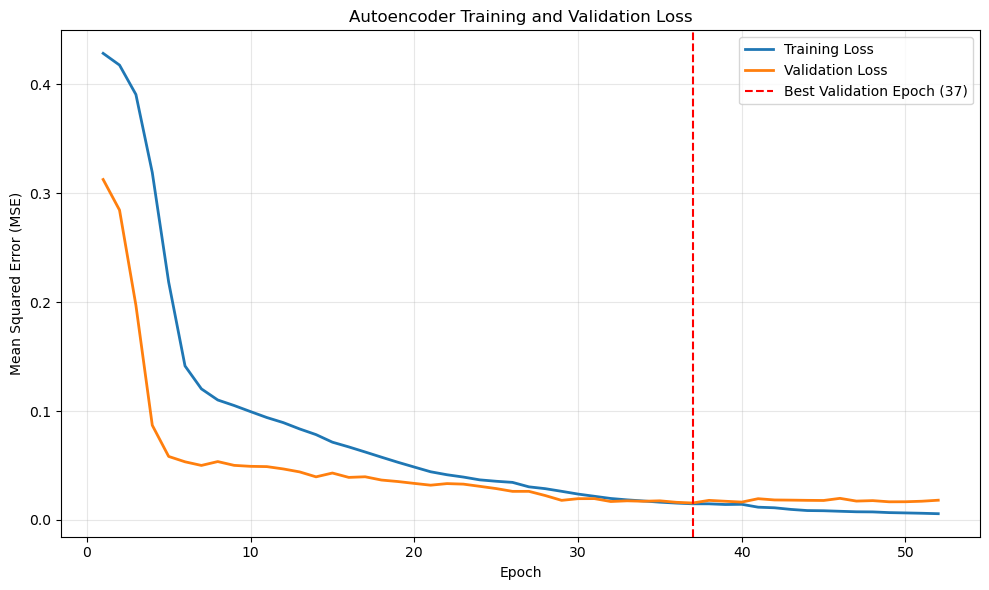

Best validation epoch: 37
Best validation loss: 0.015549
Learning curve saved successfully!


In [15]:

# Step 15: Visualize Autoencoder training and validation losses

import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(1, len(train_losses) + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    train_losses,
    label="Training Loss",
    linewidth=2
)

plt.plot(
    epochs,
    val_losses,
    label="Validation Loss",
    linewidth=2
)

# Mark the best validation epoch
best_epoch = np.argmin(val_losses) + 1

plt.axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Validation Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Autoencoder Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save for our report
plt.savefig(
    project_path / "results" / "autoencoder_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Best validation epoch:", best_epoch)
print("Best validation loss:", round(min(val_losses), 6))
print("Learning curve saved successfully!")


In [16]:

# Step 16: Calculate Autoencoder reconstruction errors

import numpy as np
import pandas as pd
import torch

# Switch model to evaluation mode
autoencoder.eval()

# Convert validation measurements to PyTorch tensor
val_input_tensor = torch.tensor(
    X_val_scaled,
    dtype=torch.float32
)

# Reconstruct validation measurements
with torch.no_grad():
    reconstructed_val = autoencoder(
        val_input_tensor
    ).numpy()

# Calculate MSE for EACH validation record
val_reconstruction_errors = np.mean(
    (X_val_scaled - reconstructed_val) ** 2,
    axis=1
)

# Separate reconstruction errors by actual label
normal_errors = val_reconstruction_errors[
    y_val.to_numpy() == 0
]

fault_errors = val_reconstruction_errors[
    y_val.to_numpy() == 1
]

print("AUTOENCODER RECONSTRUCTION ERROR ANALYSIS")
print("-----------------------------------------")

print("\nNORMAL OPERATION:")
print("Records:", len(normal_errors))
print("Mean error:", round(normal_errors.mean(), 6))
print("Median error:", round(np.median(normal_errors), 6))

print("\nFAULT CONDITIONS:")
print("Records:", len(fault_errors))
print("Mean error:", round(fault_errors.mean(), 6))
print("Median error:", round(np.median(fault_errors), 6))

print("\nError ratio (Fault Mean / Normal Mean):",
      round(
          fault_errors.mean() / normal_errors.mean(),
          2
      ) if normal_errors.mean() > 0 else "Undefined")


AUTOENCODER RECONSTRUCTION ERROR ANALYSIS
-----------------------------------------

NORMAL OPERATION:
Records: 122
Mean error: 0.015549
Median error: 0.014283

FAULT CONDITIONS:
Records: 1823
Mean error: 27547120000000.0
Median error: 6441366000000.0

Error ratio (Fault Mean / Normal Mean): 1771651300000000.0


In [17]:

# Step 17: Investigate extreme Autoencoder errors

import numpy as np
import pandas as pd

# Calculate reconstruction error for each sensor
sensor_errors = (
    X_val_scaled - reconstructed_val
) ** 2

# Average error across fault records, for each sensor
fault_mask = y_val.to_numpy() == 1

mean_fault_sensor_errors = sensor_errors[
    fault_mask
].mean(axis=0)

# Get normal training standard deviations
normal_sensor_std = X_normal_train.std(axis=0)

# Create a table showing problematic sensors
sensor_analysis = pd.DataFrame({
    "Sensor": feature_columns,
    "Normal_Training_Std": normal_sensor_std.to_numpy(),
    "Mean_Fault_Reconstruction_Error": mean_fault_sensor_errors
})

sensor_analysis = sensor_analysis.sort_values(
    "Mean_Fault_Reconstruction_Error",
    ascending=False
).reset_index(drop=True)

print("TOP 10 SENSORS CONTRIBUTING TO FAULT ERRORS")
display(sensor_analysis.head(10))

print("\nNumber of constant sensors during normal training:",
      (normal_sensor_std == 0).sum())

print("\nNumber of sensors with very small standard deviation:",
      (normal_sensor_std < 1e-5).sum())

print("\nMaximum absolute standardized fault value:",
      np.max(np.abs(X_val_scaled[fault_mask])))


TOP 10 SENSORS CONTRIBUTING TO FAULT ERRORS


,Sensor,Normal_Training_Std,Mean_Fault_Reconstruction_Error
0,STRB,4.863893e-17,2.449080e+15
1,RM4,1.389684e-17,1.875944e+14
2,RM1,5.862728e-18,6.303007e+12
3,WSTB,2.056558e-03,9.367521e+11
4,WSTA,2.031217e-03,3.627426e+11
5,RC131,0.000000e+00,2.264974e+11
6,VOID,3.036897e-06,5.480844e+09
7,DNBR,6.887954e-04,3.509428e+09
8,RC87,0.000000e+00,2.643281e+09
9,DTHY,7.328410e-19,2.066134e+09



Number of constant sensors during normal training: 48

Number of sensors with very small standard deviation: 56

Maximum absolute standardized fault value: 148362690.0


In [18]:

# Step 18: Correct Autoencoder feature scaling

import numpy as np
from sklearn.preprocessing import StandardScaler

# Fit the scaler on TRAINING data only
# This includes normal and fault training records.
scaler_ae_fixed = StandardScaler()
scaler_ae_fixed.fit(X_train)

# Train the Autoencoder on NORMAL records only
X_normal_train_fixed = scaler_ae_fixed.transform(
    X_train.loc[y_train == 0]
).astype(np.float32)

# Normal validation records for early stopping
X_normal_val_fixed = scaler_ae_fixed.transform(
    X_val.loc[y_val == 0]
).astype(np.float32)

# All validation records for anomaly evaluation
X_val_fixed = scaler_ae_fixed.transform(
    X_val
).astype(np.float32)

print("CORRECTED AUTOENCODER DATA PREPARATION")
print("--------------------------------------")

print("Normal training shape:", X_normal_train_fixed.shape)
print("Normal validation shape:", X_normal_val_fixed.shape)
print("All validation shape:", X_val_fixed.shape)

print("\nMaximum absolute standardized fault value:")

fault_mask = y_val.to_numpy() == 1

print(
    np.max(
        np.abs(X_val_fixed[fault_mask])
    )
)

print("\nAll values finite:",
      np.isfinite(X_val_fixed).all())

print("\nScaler fitted on training data only!")
print("No validation or test data used for fitting.")


CORRECTED AUTOENCODER DATA PREPARATION
--------------------------------------
Normal training shape: (365, 96)
Normal validation shape: (122, 96)
All validation shape: (1945, 96)

Maximum absolute standardized fault value:
631070460000.0

All values finite: True

Scaler fitted on training data only!
No validation or test data used for fitting.


In [19]:

# Step 19: Investigate extreme values after corrected scaling

import numpy as np
import pandas as pd

# Select fault records from validation
fault_mask = y_val.to_numpy() == 1

# Find maximum standardized value for each sensor
max_scaled_values = np.max(
    np.abs(X_val_fixed[fault_mask]),
    axis=0
)

# Create sensor comparison table
scaling_analysis = pd.DataFrame({
    "Sensor": feature_columns,
    "Training_Std": X_train.std(axis=0).to_numpy(),
    "Training_Min": X_train.min(axis=0).to_numpy(),
    "Training_Max": X_train.max(axis=0).to_numpy(),
    "Validation_Fault_Min": X_val.loc[y_val == 1].min(axis=0).to_numpy(),
    "Validation_Fault_Max": X_val.loc[y_val == 1].max(axis=0).to_numpy(),
    "Max_Abs_Scaled_Value": max_scaled_values
})

# Sort by largest standardized values
scaling_analysis = scaling_analysis.sort_values(
    "Max_Abs_Scaled_Value",
    ascending=False
).reset_index(drop=True)

print("TOP 10 MOST EXTREME SENSORS")
display(scaling_analysis.head(10))

print("\nSensors with almost zero training variation:")
print(
    (X_train.std(axis=0) < 1e-8).sum()
)


TOP 10 MOST EXTREME SENSORS


,Sensor,Training_Std,Training_Min,Training_Max,Validation_Fault_Min,Validation_Fault_Max,Max_Abs_Scaled_Value
0,RM1,0.000012,1.100000e-03,0.001180,1.100000e-03,7.526202e+06,6.310705e+11
1,STRB,0.010487,5.154753e-06,0.021269,2.126906e-02,1.483627e+08,1.414856e+10
2,DWB,0.144744,1.077043e-05,0.707145,1.691945e-05,4.208180e+04,2.907555e+05
3,RM4,592.396844,4.400000e-02,2893.178223,4.400000e-02,2.528566e+07,4.268665e+04
4,DTHY,6.427886,1.392045e-04,43.760983,1.689467e-04,7.473339e+04,1.162708e+04
5,RRCA,0.286589,4.785288e-02,1.176871,-9.681090e-02,1.000000e+00,3.530721e+00
6,WRCA,4733.255617,7.903295e+02,19436.990234,-1.598911e+03,1.651582e+04,3.530721e+00
7,WCHG,17.234246,-5.413075e-07,68.699997,-5.413075e-07,6.870000e+01,3.336934e+00
8,WSTB,1643.977127,-5.464865e+03,4598.936523,1.287444e+01,5.621253e+03,2.591747e+00
9,RBLK,236.963034,6.668071e-01,848.847656,2.000421e+00,8.128400e+02,2.394655e+00



Sensors with almost zero training variation:
16


In [20]:

# Step 20: Investigate extreme sensor values by scenario

import pandas as pd

# Focus on the sensors with the largest scaling problems
problem_sensors = ["RM1", "STRB", "DWB", "RM4", "DTHY"]

# Find the maximum value of each sensor for every validation scenario
scenario_sensor_max = (
    val_df.groupby(["Scenario_ID", "Scenario"])[problem_sensors]
    .max()
    .reset_index()
)

print("MAXIMUM SENSOR VALUES BY VALIDATION SCENARIO")
display(scenario_sensor_max)

# Show the records containing the largest RM1 values
print("\nTOP 10 RECORDS WITH THE LARGEST RM1 VALUES")

extreme_records = val_df.sort_values(
    "RM1",
    ascending=False
)[
    ["Scenario_ID", "Scenario", "TIME",
     "RM1", "STRB", "DWB", "RM4", "DTHY"]
].head(10)

display(extreme_records)


MAXIMUM SENSOR VALUES BY VALIDATION SCENARIO


,Scenario_ID,Scenario,RM1,STRB,DWB,RM4,DTHY
0,0,00 - Normal Operation,1.100000e-03,2.126906e-02,0.000017,4.400000e-02,0.000169
1,7,07 - Loss of Flow (Locked Rotor),1.100000e-03,2.126906e-02,0.000018,4.400000e-02,0.000203
2,18,18 - Fuel Handling Accident in Containment,7.526202e+06,1.483627e+08,42081.796875,4.400000e-02,60780.269531
3,19,19 - Fuel Handling Accident in Auxiliary Building,1.100000e-03,2.126906e-02,6180.274414,2.528566e+07,74733.390625



TOP 10 RECORDS WITH THE LARGEST RM1 VALUES


,Scenario_ID,Scenario,TIME,RM1,STRB,DWB,RM4,DTHY
9124,18,18 - Fuel Handling Accident in Containment,607,7526202.0,148362688.0,42081.796875,0.044,60780.269531
9123,18,18 - Fuel Handling Accident in Containment,606,7513805.5,148118256.0,42012.476562,0.044,60682.523438
9122,18,18 - Fuel Handling Accident in Containment,605,7501409.5,147873856.0,41943.164062,0.044,60584.781250
9121,18,18 - Fuel Handling Accident in Containment,604,7489012.5,147629424.0,41873.847656,0.044,60487.031250
9120,18,18 - Fuel Handling Accident in Containment,603,7476616.0,147385008.0,41804.539062,0.044,60389.265625
9119,18,18 - Fuel Handling Accident in Containment,602,7464218.0,147140576.0,41735.218750,0.044,60291.496094
9118,18,18 - Fuel Handling Accident in Containment,601,7451822.0,146896176.0,41665.910156,0.044,60193.718750
9117,18,18 - Fuel Handling Accident in Containment,600,7439426.0,146651744.0,41596.593750,0.044,60095.929688
9116,18,18 - Fuel Handling Accident in Containment,599,7427028.5,146407328.0,41527.273438,0.044,59998.140625
9115,18,18 - Fuel Handling Accident in Containment,598,7414632.0,146162912.0,41457.964844,0.044,59900.339844


In [21]:

# Step 21: Robust preprocessing for the Autoencoder

import numpy as np
from sklearn.preprocessing import RobustScaler

# Signed logarithm transformation
def signed_log_transform(data):
    return np.sign(data) * np.log1p(np.abs(data))

# Transform raw sensor measurements
X_train_log = signed_log_transform(
    X_train.to_numpy(dtype=np.float64)
)

X_val_log = signed_log_transform(
    X_val.to_numpy(dtype=np.float64)
)

# Fit scaler using TRAINING data only
robust_scaler_ae = RobustScaler(
    quantile_range=(10, 90)
)

robust_scaler_ae.fit(X_train_log)

# Transform the datasets
X_train_robust = robust_scaler_ae.transform(
    X_train_log
).astype(np.float32)

X_val_robust = robust_scaler_ae.transform(
    X_val_log
).astype(np.float32)

# Select normal records for Autoencoder training
X_normal_train_robust = X_train_robust[
    y_train.to_numpy() == 0
]

X_normal_val_robust = X_val_robust[
    y_val.to_numpy() == 0
]

fault_mask = y_val.to_numpy() == 1

print("ROBUST AUTOENCODER PREPROCESSING")
print("--------------------------------")

print("Normal training shape:",
      X_normal_train_robust.shape)

print("Normal validation shape:",
      X_normal_val_robust.shape)

print("All validation shape:",
      X_val_robust.shape)

print("\nMaximum absolute standardized fault value:",
      np.max(np.abs(X_val_robust[fault_mask])))

print("\nAll values finite:",
      np.isfinite(X_val_robust).all())

print("\n99th percentile of absolute validation values:",
      np.percentile(np.abs(X_val_robust), 99))


ROBUST AUTOENCODER PREPROCESSING
--------------------------------
Normal training shape: (365, 96)
Normal validation shape: (122, 96)
All validation shape: (1945, 96)

Maximum absolute standardized fault value: 4202.4473

All values finite: True

99th percentile of absolute validation values: 107.04765937805176


In [22]:

# Step 22: Clip extreme transformed sensor values

import numpy as np

clip_limit = 10.0

# Clip both training and validation consistently
X_train_ae_final = np.clip(
    X_train_robust,
    -clip_limit,
    clip_limit
).astype(np.float32)

X_val_ae_final = np.clip(
    X_val_robust,
    -clip_limit,
    clip_limit
).astype(np.float32)

# Normal measurements for Autoencoder training
X_normal_train_ae_final = X_train_ae_final[
    y_train.to_numpy() == 0
]

# Normal measurements for early stopping
X_normal_val_ae_final = X_val_ae_final[
    y_val.to_numpy() == 0
]

print("FINAL AUTOENCODER PREPROCESSING")
print("-------------------------------")

print("Normal training:",
      X_normal_train_ae_final.shape)

print("Normal validation:",
      X_normal_val_ae_final.shape)

print("All validation:",
      X_val_ae_final.shape)

print("\nMaximum absolute value:",
      np.max(np.abs(X_val_ae_final)))

print("All values finite:",
      np.isfinite(X_val_ae_final).all())

print("\nPercentage of validation values clipped:",
      round(
          100 * np.mean(np.abs(X_val_robust) > clip_limit),
          2
      ),
      "%"
)


FINAL AUTOENCODER PREPROCESSING
-------------------------------
Normal training: (365, 96)
Normal validation: (122, 96)
All validation: (1945, 96)

Maximum absolute value: 10.0
All values finite: True

Percentage of validation values clipped: 2.6 %


In [23]:

# Step 23: Retrain Autoencoder using corrected preprocessing

import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Create a FRESH Autoencoder
autoencoder_fixed = NuclearAutoencoder(
    input_dim=X_normal_train_ae_final.shape[1]
)

# Prepare normal-operation measurements
train_tensor_fixed = torch.tensor(
    X_normal_train_ae_final,
    dtype=torch.float32
)

val_tensor_fixed = torch.tensor(
    X_normal_val_ae_final,
    dtype=torch.float32
)

train_loader_fixed = DataLoader(
    TensorDataset(train_tensor_fixed),
    batch_size=32,
    shuffle=True
)

# Training settings
criterion_fixed = nn.MSELoss()

optimizer_fixed = torch.optim.Adam(
    autoencoder_fixed.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

max_epochs = 200
patience = 15

best_val_loss_fixed = float("inf")
best_model_state_fixed = None
best_epoch_fixed = 0
epochs_without_improvement = 0

train_losses_fixed = []
val_losses_fixed = []

# Training loop
for epoch in range(max_epochs):

    autoencoder_fixed.train()
    total_train_loss = 0

    for (batch,) in train_loader_fixed:

        optimizer_fixed.zero_grad()

        reconstructed = autoencoder_fixed(batch)

        loss = criterion_fixed(reconstructed, batch)

        loss.backward()
        optimizer_fixed.step()

        total_train_loss += loss.item() * len(batch)

    avg_train_loss = total_train_loss / len(train_tensor_fixed)

    # Validation using NORMAL measurements only
    autoencoder_fixed.eval()

    with torch.no_grad():
        reconstructed_val = autoencoder_fixed(val_tensor_fixed)

        avg_val_loss = criterion_fixed(
            reconstructed_val,
            val_tensor_fixed
        ).item()

    train_losses_fixed.append(avg_train_loss)
    val_losses_fixed.append(avg_val_loss)

    # Save the best model
    if avg_val_loss < best_val_loss_fixed - 1e-6:

        best_val_loss_fixed = avg_val_loss

        best_model_state_fixed = copy.deepcopy(
            autoencoder_fixed.state_dict()
        )

        best_epoch_fixed = epoch + 1
        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Train Loss = {avg_train_loss:.6f}, "
            f"Val Loss = {avg_val_loss:.6f}"
        )

    if epochs_without_improvement >= patience:
        print("\nEarly stopping triggered!")
        break

# Restore the best weights
autoencoder_fixed.load_state_dict(best_model_state_fixed)
autoencoder_fixed.eval()

print("\nCORRECTED AUTOENCODER TRAINING COMPLETE")
print("--------------------------------------")
print("Total epochs:", len(train_losses_fixed))
print("Best epoch:", best_epoch_fixed)
print("Best validation loss:", round(best_val_loss_fixed, 6))


Epoch 10: Train Loss = 0.000938, Val Loss = 0.001200
Epoch 20: Train Loss = 0.000927, Val Loss = 0.001224
Epoch 30: Train Loss = 0.000898, Val Loss = 0.001177
Epoch 40: Train Loss = 0.000051, Val Loss = 0.000029
Epoch 50: Train Loss = 0.000037, Val Loss = 0.000038

Early stopping triggered!

CORRECTED AUTOENCODER TRAINING COMPLETE
--------------------------------------
Total epochs: 57
Best epoch: 42
Best validation loss: 1.8e-05


In [24]:

# Step 24: Evaluate corrected Autoencoder fault detection

import numpy as np
import torch

from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

autoencoder_fixed.eval()

# Convert normal training and validation data to tensors
train_input = torch.tensor(
    X_normal_train_ae_final,
    dtype=torch.float32
)

val_input = torch.tensor(
    X_val_ae_final,
    dtype=torch.float32
)

# Reconstruct both datasets
with torch.no_grad():
    train_reconstructed = autoencoder_fixed(
        train_input
    ).numpy()

    val_reconstructed = autoencoder_fixed(
        val_input
    ).numpy()

# Calculate reconstruction error for each record
train_ae_errors = np.mean(
    (X_normal_train_ae_final - train_reconstructed) ** 2,
    axis=1
)

val_ae_errors = np.mean(
    (X_val_ae_final - val_reconstructed) ** 2,
    axis=1
)

# Set anomaly threshold using NORMAL TRAINING data only
ae_threshold = np.percentile(
    train_ae_errors,
    99
)

# Predict: 0 = Normal, 1 = Fault
ae_val_pred = (
    val_ae_errors > ae_threshold
).astype(int)

print("CORRECTED AUTOENCODER - VALIDATION RESULTS")
print("------------------------------------------")

print("Anomaly threshold:", round(ae_threshold, 8))

print("\nBalanced Accuracy:",
      round(balanced_accuracy_score(y_val, ae_val_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, ae_val_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_val,
    ae_val_pred,
    labels=[0, 1],
    target_names=["Normal", "Fault"],
    zero_division=0
))

# Analyze performance by scenario
ae_val_analysis = val_df.copy()
ae_val_analysis["Prediction"] = ae_val_pred
ae_val_analysis["Reconstruction_Error"] = val_ae_errors

scenario_results_ae = (
    ae_val_analysis.groupby(["Scenario_ID", "Scenario"])
    .apply(
        lambda group: pd.Series({
            "Records": len(group),
            "Correct": (
                group["Label"] == group["Prediction"]
            ).sum(),
            "Accuracy": (
                group["Label"] == group["Prediction"]
            ).mean(),
            "Mean_Error": group["Reconstruction_Error"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

print("\nAUTOENCODER PERFORMANCE BY SCENARIO")
display(scenario_results_ae.round(4))


CORRECTED AUTOENCODER - VALIDATION RESULTS
------------------------------------------
Anomaly threshold: 0.00029685

Balanced Accuracy: 1.0

Confusion Matrix:
[[ 122    0]
 [   0 1823]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       122
       Fault       1.00      1.00      1.00      1823

    accuracy                           1.00      1945
   macro avg       1.00      1.00      1.00      1945
weighted avg       1.00      1.00      1.00      1945


AUTOENCODER PERFORMANCE BY SCENARIO


,Scenario_ID,Scenario,Records,Correct,Accuracy,Mean_Error
0,0,00 - Normal Operation,122.0,122.0,1.0,0.0000
1,7,07 - Loss of Flow (Locked Rotor),607.0,607.0,1.0,1.9234
2,18,18 - Fuel Handling Accident in Containment,607.0,607.0,1.0,4.1666
3,19,19 - Fuel Handling Accident in Auxiliary Building,609.0,609.0,1.0,3.1248


In [25]:

# Step 25: Autoencoder robustness check

import numpy as np
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix
)

# Sensors with unusually extreme values
extreme_sensors = ["RM1", "STRB", "DWB", "RM4", "DTHY"]

# Keep all other sensors
keep_indices = [
    i for i, sensor in enumerate(feature_columns)
    if sensor not in extreme_sensors
]

# Calculate errors using only the remaining sensors
train_ae_errors_robust = np.mean(
    (
        X_normal_train_ae_final[:, keep_indices]
        - train_reconstructed[:, keep_indices]
    ) ** 2,
    axis=1
)

val_ae_errors_robust = np.mean(
    (
        X_val_ae_final[:, keep_indices]
        - val_reconstructed[:, keep_indices]
    ) ** 2,
    axis=1
)

# Recalculate threshold using normal TRAINING records
robust_threshold = np.percentile(
    train_ae_errors_robust,
    99
)

# Make predictions
ae_val_pred_robust = (
    val_ae_errors_robust > robust_threshold
).astype(int)

print("AUTOENCODER ROBUSTNESS CHECK")
print("----------------------------")

print("Excluded sensors:", extreme_sensors)
print("Remaining sensors:", len(keep_indices))

print("\nOriginal balanced accuracy:",
      round(balanced_accuracy_score(y_val, ae_val_pred), 4))

print("Robustness-check balanced accuracy:",
      round(balanced_accuracy_score(y_val, ae_val_pred_robust), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val,
    ae_val_pred_robust,
    labels=[0, 1]
))

# Check individual validation scenarios
robust_analysis = val_df[
    ["Scenario_ID", "Scenario", "Label"]
].copy()

robust_analysis["Prediction"] = ae_val_pred_robust

print("\nACCURACY BY SCENARIO")
display(
    robust_analysis.groupby(
        ["Scenario_ID", "Scenario"]
    ).apply(
        lambda group: (
            group["Label"] == group["Prediction"]
        ).mean(),
        include_groups=False
    ).reset_index(name="Accuracy").round(4)
)


AUTOENCODER ROBUSTNESS CHECK
----------------------------
Excluded sensors: ['RM1', 'STRB', 'DWB', 'RM4', 'DTHY']
Remaining sensors: 91

Original balanced accuracy: 1.0
Robustness-check balanced accuracy: 0.6681

Confusion Matrix:
[[ 122    0]
 [1210  613]]

ACCURACY BY SCENARIO


,Scenario_ID,Scenario,Accuracy
0,0,00 - Normal Operation,1.0000
1,7,07 - Loss of Flow (Locked Rotor),1.0000
2,18,18 - Fuel Handling Accident in Containment,0.0049
3,19,19 - Fuel Handling Accident in Auxiliary Building,0.0049


FINAL VALIDATION MODEL COMPARISON


,Model,Validation_Balanced_Accuracy
0,Random Forest,0.7216
1,XGBoost,0.9467
2,Autoencoder,1.0000
3,Autoencoder (91-sensor score),0.6681


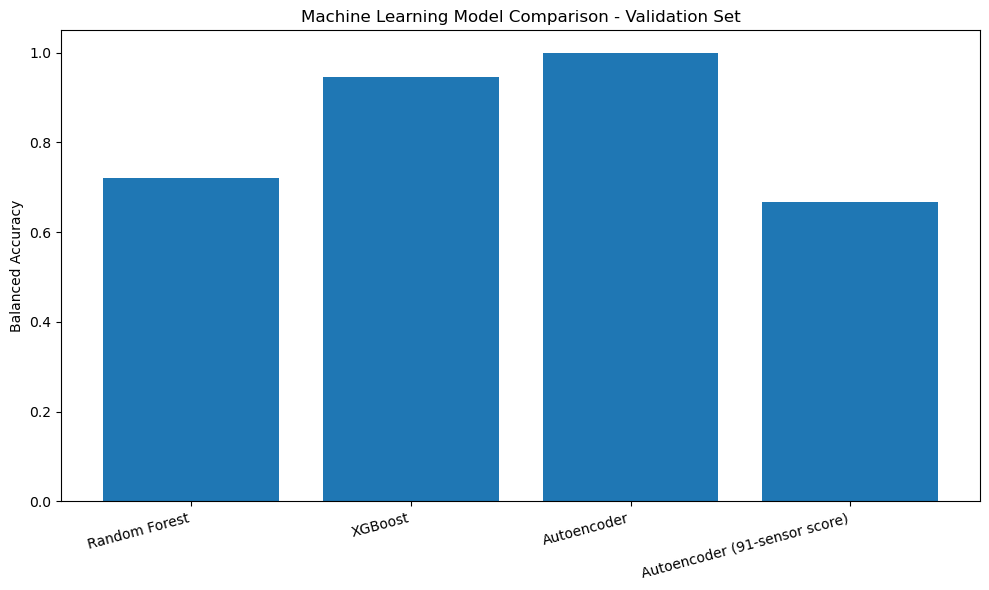


Model comparison saved successfully!


In [26]:

# Step 26: Compare models and save validation results

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score

model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "Autoencoder",
        "Autoencoder (91-sensor score)"
    ],
    "Validation_Balanced_Accuracy": [
        balanced_accuracy_score(y_val, rf_val_pred),
        balanced_accuracy_score(y_val, xgb_val_pred),
        balanced_accuracy_score(y_val, ae_val_pred),
        balanced_accuracy_score(y_val, ae_val_pred_robust)
    ]
})

print("FINAL VALIDATION MODEL COMPARISON")
display(model_comparison.round(4))

# Plot comparison
plt.figure(figsize=(10, 6))

plt.bar(
    model_comparison["Model"],
    model_comparison["Validation_Balanced_Accuracy"]
)

plt.ylabel("Balanced Accuracy")
plt.title("Machine Learning Model Comparison - Validation Set")
plt.ylim(0, 1.05)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()

plt.savefig(
    project_path / "results" / "advanced_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save numerical comparison
model_comparison.to_csv(
    project_path / "results" / "advanced_model_comparison.csv",
    index=False
)

print("\nModel comparison saved successfully!")


In [27]:

# Step 27: Final evaluation on untouched test scenarios

import numpy as np
import torch
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

# ------------------------------
# 1. Random Forest
# ------------------------------

rf_test_pred = rf_best.predict(X_test)

# ------------------------------
# 2. XGBoost
# ------------------------------

xgb_test_pred = xgb_best.predict(X_test)

# ------------------------------
# 3. Autoencoder
# ------------------------------

# Apply the SAME preprocessing used during training
X_test_log = signed_log_transform(
    X_test.to_numpy(dtype=np.float64)
)

X_test_robust = robust_scaler_ae.transform(
    X_test_log
)

X_test_ae_final = np.clip(
    X_test_robust,
    -clip_limit,
    clip_limit
).astype(np.float32)

# Reconstruct test measurements
autoencoder_fixed.eval()

with torch.no_grad():
    test_input = torch.tensor(
        X_test_ae_final,
        dtype=torch.float32
    )

    test_reconstructed = autoencoder_fixed(
        test_input
    ).numpy()

# Calculate reconstruction errors
test_ae_errors = np.mean(
    (X_test_ae_final - test_reconstructed) ** 2,
    axis=1
)

# Use threshold already selected from training data
ae_test_pred = (
    test_ae_errors > ae_threshold
).astype(int)

# ------------------------------
# 4. Compare models
# ------------------------------

test_predictions = {
    "Random Forest": rf_test_pred,
    "XGBoost": xgb_test_pred,
    "Autoencoder": ae_test_pred
}

print("FINAL TEST-SET RESULTS")
print("======================")

for model_name, predictions in test_predictions.items():

    score = balanced_accuracy_score(
        y_test,
        predictions
    )

    print(f"\n{model_name}")
    print("-" * 35)

    print("Balanced Accuracy:", round(score, 4))

    print("Confusion Matrix:")
    print(
        confusion_matrix(
            y_test,
            predictions,
            labels=[0, 1]
        )
    )

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["Normal", "Fault"],
            zero_division=0
        )
    )


FINAL TEST-SET RESULTS

Random Forest
-----------------------------------
Balanced Accuracy: 0.8988
Confusion Matrix:
[[ 122    0]
 [ 369 1454]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.25      1.00      0.40       122
       Fault       1.00      0.80      0.89      1823

    accuracy                           0.81      1945
   macro avg       0.62      0.90      0.64      1945
weighted avg       0.95      0.81      0.86      1945


XGBoost
-----------------------------------
Balanced Accuracy: 1.0
Confusion Matrix:
[[ 122    0]
 [   0 1823]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       122
       Fault       1.00      1.00      1.00      1823

    accuracy                           1.00      1945
   macro avg       1.00      1.00      1.00      1945
weighted avg       1.00      1.00      1.00      1945


Autoencoder
---------------------------

In [28]:

# Step 28: Final test performance by scenario

import pandas as pd
from sklearn.metrics import balanced_accuracy_score

# Create test results table
test_analysis = test_df[
    ["Scenario_ID", "Scenario", "Label"]
].copy()

test_analysis["Random_Forest"] = rf_test_pred
test_analysis["XGBoost"] = xgb_test_pred
test_analysis["Autoencoder"] = ae_test_pred

# Calculate accuracy for each scenario
scenario_test_results = (
    test_analysis.groupby(["Scenario_ID", "Scenario"])
    .apply(
        lambda group: pd.Series({
            "Records": len(group),

            "RF_Accuracy": (
                group["Label"] == group["Random_Forest"]
            ).mean(),

            "XGB_Accuracy": (
                group["Label"] == group["XGBoost"]
            ).mean(),

            "AE_Accuracy": (
                group["Label"] == group["Autoencoder"]
            ).mean()
        }),
        include_groups=False
    )
    .reset_index()
)

print("FINAL TEST PERFORMANCE BY SCENARIO")
display(scenario_test_results.round(4))

# Save results
scenario_test_results.to_csv(
    project_path / "results" / "advanced_test_scenario_results.csv",
    index=False
)

print("\nScenario results saved successfully!")


FINAL TEST PERFORMANCE BY SCENARIO


,Scenario_ID,Scenario,Records,RF_Accuracy,XGB_Accuracy,AE_Accuracy
0,0,00 - Normal Operation,122.0,1.0000,1.0,1.0
1,1,01 - Loss of Coolant Accident (Hot Leg),605.0,0.9950,1.0,1.0
2,2,02 - Loss of Coolant Accident (Cold Leg),602.0,0.9983,1.0,1.0
3,16,16 - Containment Failure or Spark for H2 Deton...,616.0,0.4075,1.0,1.0



Scenario results saved successfully!


TOP 15 MOST IMPORTANT SENSORS


,Sensor,Importance
0,DNBR,0.275149
1,WSTB,0.143459
2,THB,0.073353
3,WFWA,0.060549
4,WFWB,0.056335
5,FRCL,0.048827
6,DWB,0.042253
7,RM2,0.039491
8,RC87,0.034789
9,DTHY,0.028352


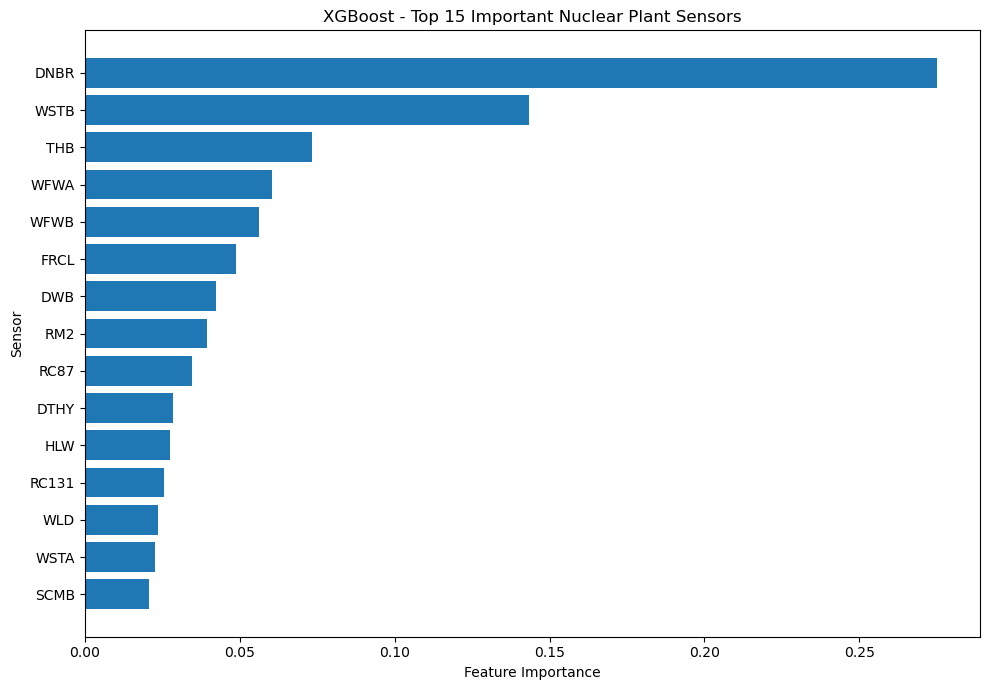


Feature importance analysis saved successfully!


In [29]:

# Step 29: XGBoost feature importance analysis

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance from trained XGBoost
importance_df = pd.DataFrame({
    "Sensor": feature_columns,
    "Importance": xgb_best.feature_importances_
})

# Sort most important sensors first
importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("TOP 15 MOST IMPORTANT SENSORS")
display(importance_df.head(15).round(6))

# Plot the top 15 sensors
top_features = importance_df.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Sensor"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Sensor")
plt.title("XGBoost - Top 15 Important Nuclear Plant Sensors")
plt.tight_layout()

# Save results
plt.savefig(
    project_path / "results" / "advanced_xgb_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

importance_df.to_csv(
    project_path / "results" / "advanced_xgb_feature_importance.csv",
    index=False
)

plt.show()

print("\nFeature importance analysis saved successfully!")


In [30]:
# Step 30: Save final advanced models and artifacts

import joblib
import json
import torch
from pathlib import Path

models_path = project_path / "models"
models_path.mkdir(parents=True, exist_ok=True)

# -----------------------------
# Save classical ML models
# -----------------------------
joblib.dump(
    rf_best,
    models_path / "advanced_random_forest.pkl"
)

joblib.dump(
    xgb_best,
    models_path / "advanced_xgboost.pkl"
)

# -----------------------------
# Save Autoencoder weights
# -----------------------------
torch.save(
    autoencoder_fixed.state_dict(),
    models_path / "advanced_autoencoder.pth"
)

# -----------------------------
# Save preprocessing objects
# -----------------------------
joblib.dump(
    robust_scaler_ae,
    models_path / "advanced_autoencoder_robust_scaler.pkl"
)

# -----------------------------
# Save feature names
# -----------------------------
joblib.dump(
    feature_columns,
    models_path / "advanced_feature_names.pkl"
)

# -----------------------------
# Save Autoencoder settings
# -----------------------------
autoencoder_metadata = {
    "input_dim": len(feature_columns),
    "clip_limit": float(clip_limit),
    "threshold": float(ae_threshold),
    "best_epoch": int(best_epoch_fixed),
    "best_validation_loss": float(best_val_loss_fixed),
    "preprocessing": [
        "signed_log_transform",
        "RobustScaler(quantile_range=(10, 90))",
        "clip to [-10, 10]"
    ]
}

with open(models_path / "advanced_autoencoder_metadata.json", "w") as f:
    json.dump(autoencoder_metadata, f, indent=4)

# -----------------------------
# Save overall experiment summary
# -----------------------------
experiment_summary = {
    "random_forest_validation_balanced_accuracy": float(
        balanced_accuracy_score(y_val, rf_val_pred)
    ),
    "xgboost_validation_balanced_accuracy": float(
        balanced_accuracy_score(y_val, xgb_val_pred)
    ),
    "autoencoder_validation_balanced_accuracy": float(
        balanced_accuracy_score(y_val, ae_val_pred)
    ),
    "random_forest_test_balanced_accuracy": float(
        balanced_accuracy_score(y_test, rf_test_pred)
    ),
    "xgboost_test_balanced_accuracy": float(
        balanced_accuracy_score(y_test, xgb_test_pred)
    ),
    "autoencoder_test_balanced_accuracy": float(
        balanced_accuracy_score(y_test, ae_test_pred)
    )
}

with open(models_path / "advanced_experiment_summary.json", "w") as f:
    json.dump(experiment_summary, f, indent=4)

print("FINAL ADVANCED MODELS SAVED SUCCESSFULLY!")
print("\nSaved files:")

saved_files = [
    "advanced_random_forest.pkl",
    "advanced_xgboost.pkl",
    "advanced_autoencoder.pth",
    "advanced_autoencoder_robust_scaler.pkl",
    "advanced_feature_names.pkl",
    "advanced_autoencoder_metadata.json",
    "advanced_experiment_summary.json"
]

for file_name in saved_files:
    print("-", file_name)

FINAL ADVANCED MODELS SAVED SUCCESSFULLY!

Saved files:
- advanced_random_forest.pkl
- advanced_xgboost.pkl
- advanced_autoencoder.pth
- advanced_autoencoder_robust_scaler.pkl
- advanced_feature_names.pkl
- advanced_autoencoder_metadata.json
- advanced_experiment_summary.json


In [31]:

# Step 31: Create the final advanced experiment summary

import pandas as pd
from sklearn.metrics import balanced_accuracy_score

final_summary = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "Autoencoder"
    ],
    "Validation_Balanced_Accuracy": [
        balanced_accuracy_score(y_val, rf_val_pred),
        balanced_accuracy_score(y_val, xgb_val_pred),
        balanced_accuracy_score(y_val, ae_val_pred)
    ],
    "Test_Balanced_Accuracy": [
        balanced_accuracy_score(y_test, rf_test_pred),
        balanced_accuracy_score(y_test, xgb_test_pred),
        balanced_accuracy_score(y_test, ae_test_pred)
    ],
    "Strength": [
        "Simple baseline and interpretable model",
        "Strong performance on unseen fault scenarios",
        "Learns normal-operation reconstruction patterns"
    ],
    "Limitation": [
        "Misses some unseen fault types",
        "Requires further independent validation",
        "Sensitive to specific sensors and preprocessing"
    ]
})

print("FINAL ADVANCED MACHINE LEARNING EXPERIMENT SUMMARY")
print("=================================================")

display(final_summary.round(4))

# Save summary
output_path = (
    project_path / "results" /
    "final_advanced_experiment_summary.csv"
)

final_summary.to_csv(output_path, index=False)

print("\nFinal summary saved successfully!")
print("File:", output_path.name)

# Verify saved model artifacts exist
required_files = [
    "advanced_random_forest.pkl",
    "advanced_xgboost.pkl",
    "advanced_autoencoder.pth",
    "advanced_autoencoder_robust_scaler.pkl",
    "advanced_feature_names.pkl",
    "advanced_autoencoder_metadata.json",
    "advanced_experiment_summary.json"
]

missing_files = [
    name for name in required_files
    if not (project_path / "models" / name).exists()
]

if not missing_files:
    print("\nAll 7 advanced model files verified!")
else:
    print("\nMissing files:", missing_files)


FINAL ADVANCED MACHINE LEARNING EXPERIMENT SUMMARY


,Model,Validation_Balanced_Accuracy,Test_Balanced_Accuracy,Strength,Limitation
0,Random Forest,0.7216,0.8988,Simple baseline and interpretable model,Misses some unseen fault types
1,XGBoost,0.9467,1.0000,Strong performance on unseen fault scenarios,Requires further independent validation
2,Autoencoder,1.0000,1.0000,Learns normal-operation reconstruction patterns,Sensitive to specific sensors and preprocessing



Final summary saved successfully!
File: final_advanced_experiment_summary.csv

All 7 advanced model files verified!


In [37]:

import subprocess
import sys
from pathlib import Path

app_path = Path.cwd() / "app.py"

subprocess.Popen([
    sys.executable,
    "-m",
    "streamlit",
    "run",
    str(app_path),
    "--server.port",
    "8504"
])

print("Dashboard: http://localhost:8504")


Dashboard: http://localhost:8504


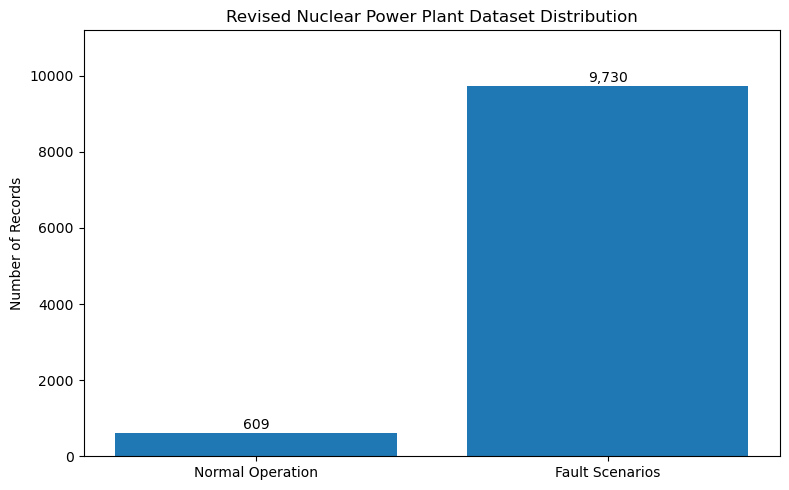

Revised dataset graph saved successfully!


In [38]:

# Revised Dataset Class Distribution

import matplotlib.pyplot as plt

normal_count = (df["Label"] == 0).sum()
fault_count = (df["Label"] == 1).sum()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Normal Operation", "Fault Scenarios"],
    [normal_count, fault_count]
)

plt.title("Revised Nuclear Power Plant Dataset Distribution")
plt.ylabel("Number of Records")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f"{int(bar.get_height()):,}",
        ha="center"
    )

plt.ylim(0, max(normal_count, fault_count) * 1.15)
plt.tight_layout()

plt.savefig(
    project_path / "results" / "revised_class_distribution.png",
    dpi=300
)

plt.show()

print("Revised dataset graph saved successfully!")


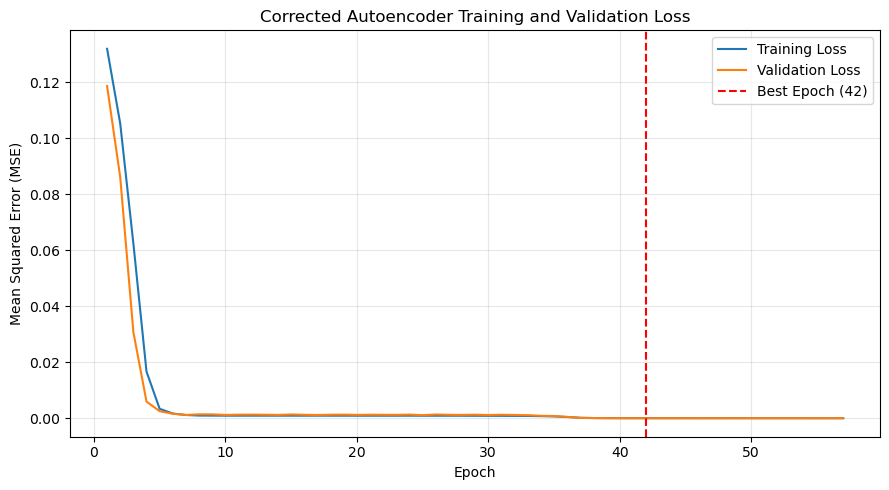

Corrected Autoencoder graph saved successfully!


In [39]:

# Corrected Autoencoder Learning Curve

import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(1, len(train_losses_fixed) + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    train_losses_fixed,
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses_fixed,
    label="Validation Loss"
)

plt.axvline(
    best_epoch_fixed,
    color="red",
    linestyle="--",
    label=f"Best Epoch ({best_epoch_fixed})"
)

plt.title("Corrected Autoencoder Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    project_path / "results" / "corrected_autoencoder_learning_curves.png",
    dpi=300
)

plt.show()

print("Corrected Autoencoder graph saved successfully!")
